# EDA - eCommerce Events History in Cosmetics Shop

**Проект:** User Action Propensity Scoring
**Источник данных:** [eCommerce Events History in Cosmetics Shop (Kaggle)](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop)

## Цель рисеча

Изучить пользовательскую активность в e-commerce продукте и оценить пригодность данных для прогнозирования двух целевых действий:

- **Purchase** — совершение покупки
- **Return** — возвращение пользователя в продукт

Для каждого действия рассматриваются горизонты прогнозирования 7 и 14 дней.

В ходе EDA хотим:

1. Оценить состав, объем и качество данных
2. Исследовать пользовательскую активность и повторные посещения
3. Сравнить частоту целевых действий для разных горизонтов и популяций
4. Определить потенциальные признаки и baseline для будущих моделей

Результаты исследования будут использованы при подготовке [ML System Design Document](../docs/ml_system_design_doc.md).

## Запуск ноутбука

**Требования:** Python 3.12, [uv](https://docs.astral.sh/uv/) и доступ к интернету для первоначальной загрузки датасета.

Из корня репозитория выполнить:

```bash
uv sync
```

После этого открыть `notebooks/01_eda_cosmetics.ipynb` в Jupyter или PyCharm и выбрать Python-интерпретатор `.venv/bin/python`.

Запустить все ячейки последовательно сверху вниз.

Датасет загружается автоматически через `kagglehub` в `data/raw/`. Для повторного запуска скачивание не требуется, если все исходные файлы уже есть

## 0. Подготовка / загрузка данных

In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

plt.rcParams["figure.figsize"] = (10, 4)

project_dir = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Не найден pyproject.toml. Открой ноутбук внутри проекта.")

data_dir = project_dir / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
raw_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

months = ["2019-Oct", "2019-Nov", "2019-Dec", "2020-Jan", "2020-Feb"]
files = [raw_dir / f"{month}.csv" for month in months]

Загрузка

In [2]:
if not all(path.exists() for path in files):
    kagglehub.dataset_download(
        "mkechinov/ecommerce-events-history-in-cosmetics-shop",
        output_dir=str(raw_dir),
    )

missing_files = [path.name for path in files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Файлы не найдены после загрузки: {missing_files}")

pd.DataFrame(
    {"file": [path.name for path in files],
     "size_mb": [round(path.stat().st_size / 1024**2, 1) for path in files]}
)

,file,size_mb
0,2019-Oct.csv,460.2
1,2019-Nov.csv,520.6
2,2019-Dec.csv,396.1
3,2020-Jan.csv,478.5
4,2020-Feb.csv,466.2


Читаем данные

In [3]:
events = (
    pl.scan_csv( # scan_csv для облегчения загрузки в память
        [str(path) for path in files],
        infer_schema_length=10000,
        schema_overrides={
            "user_id": pl.Int64,
            "user_session": pl.String,
            "event_time": pl.String,
            "event_type": pl.String,
        },
    )
    .with_columns(
        pl.col("event_time").str.slice(0, 10).str.to_date(strict=False).alias("event_date")
    )
)

events.collect_schema()

Schema([('event_time', String),
        ('event_type', String),
        ('product_id', Int64),
        ('category_id', Int64),
        ('category_code', String),
        ('brand', String),
        ('price', Float64),
        ('user_id', Int64),
        ('user_session', String),
        ('event_date', Date)])

## 1. Объем данных

Здесь оцениваем число событий, юзеров, сессий, товаров. Для целевых действий важна доля пользователей с будущими действиями

In [4]:
overview = events.select(
    pl.len().alias("events"),
    pl.col("user_id").n_unique().alias("users"),
    pl.col("user_session").n_unique().alias("sessions"),
    pl.col("product_id").n_unique().alias("products"),
    pl.col("event_date").min().alias("first_date"),
    pl.col("event_date").max().alias("last_date"),
).collect(engine="streaming")

overview.to_pandas()

,events,users,sessions,products,first_date,last_date
0,20692840,1639358,4535942,54571,2019-10-01,2020-02-29


In [5]:
event_counts = (
    events.group_by("event_type")
    .agg(
        pl.len().alias("events"),
        pl.col("user_id").n_unique().alias("users"),
    )
    .sort("events", descending=True)
    .collect(engine="streaming")
    .to_pandas()
)

event_counts

,event_type,events,users
0,view,9657821,1597754
1,cart,5768333,398308
2,remove_from_cart,3979679,183232
3,purchase,1287007,110518


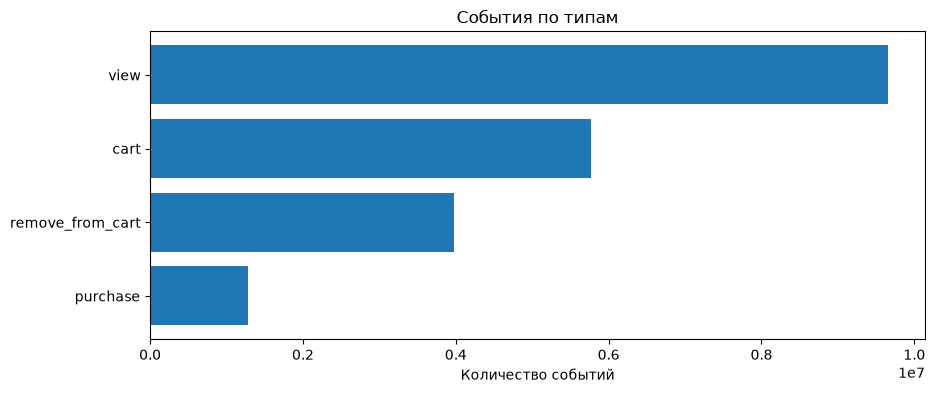

In [6]:
fig, ax = plt.subplots()
ax.barh(event_counts["event_type"], event_counts["events"])
ax.invert_yaxis()
ax.set(title="События по типам", xlabel="Количество событий")
plt.show()

Выводы:
- покупка - наиболее редкое событие
- событий покупки предположительно достаточно для задачи (~110K юзеров)
- взаимодействия с корзиной скорей всего - полезные признаки
- в данных ~1.3M событий покупок и лишь ~110K юзеров с покупками => одно оформение заказа может содержать несколько айтемов, для модели важно использовать бинарный таргет наличия хотя бы одной покупки


## 2. Качество данных

Проверяем пропуски, типы событий, формат дат и тд

In [7]:
quality = events.select(
    pl.len().alias("rows"),
    pl.col("user_id").null_count().alias("null_user_id"),
    pl.col("user_session").null_count().alias("null_session"),
    pl.col("event_date").null_count().alias("invalid_event_date"),
    pl.col("product_id").null_count().alias("null_product_id"),
    pl.col("category_code").null_count().alias("null_category_code"),
    pl.col("brand").null_count().alias("null_brand"),
    pl.col("price").null_count().alias("null_price"),
    (pl.col("price") <= 0).sum().alias("non_positive_price"),
).collect(engine="streaming")

quality.to_pandas().T.rename(columns={0: "value"})

,value
rows,20692840
null_user_id,0
null_session,4598
invalid_event_date,0
null_product_id,0
null_category_code,20339246
null_brand,8757117
null_price,0
non_positive_price,104288


In [8]:
duplicate_stats = (
    events.group_by(events.collect_schema().names())
    .len()
    .select((pl.col("len") - 1).sum().alias("duplicate_rows"))
    .collect(engine="streaming")
)

duplicate_stats.to_pandas()

,duplicate_rows
0,1109098


довольно много полных дублей событий

- основные поля заполнены хорошо
- category_code почти всегда отсутствует (можно использовать category_id)
- brand отсутствует в ~42% событиях
- есть ~100K событий с неположительной ценой

In [9]:
quality_extra = (
    events
    .select(
        pl.col("category_id").is_null().sum().alias("null_category_id"),
        (pl.col("price") == 0).sum().alias("zero_price"),
        (pl.col("price") < 0).sum().alias("negative_price"),
    )
    .collect(engine="streaming")
)

quality_extra

null_category_id,zero_price,negative_price
u32,u32,u32
0,104157,131


In [10]:
duplicate_by_type = (
    events
    .group_by(events.collect_schema().names())
    .agg(pl.len().alias("row_count"))
    .group_by("event_type")
    .agg(
        (pl.col("row_count") - 1).sum().alias("duplicates"),
        pl.col("row_count").sum().alias("events"),
    )
    .with_columns(
        (pl.col("duplicates") / pl.col("events") * 100)
        .round(2)
        .alias("duplicate_share")
    )
    .sort("duplicates", descending=True)
    .collect(engine="streaming")
)

duplicate_by_type

event_type,duplicates,events,duplicate_share
str,u32,u32,f64
"""remove_from_cart""",991820,3979679,24.92
"""cart""",115342,5768333,2.0
"""view""",1031,9657821,0.01
"""purchase""",905,1287007,0.07


- Ключевые поля для построения таргетов `purchase` и `return` заполнены. Пропуски идентификаторов сессий составляют менее 0,1%
- Поле `category_code` практически не заполнено (98,3% пропусков), однако `category_id` не содержит пропусков и может использоваться для построения категориальных признаков
- Неположительные цены встречаются в 0,5% событий. При формировании ценовых признаков такие значения планируется исключать из числовых агрегаций, сохраняя сами события в истории активности
- Найдено ~5,3% событий дублей, основная их часть приходится на `remove_from_cart`. Для покупок и просмотров доля дубликатов менее 0,1%
- Для бинарных таргетов наличие полных дубликатов несущественно, однако при построении количественных поведенческих признаков надо учитывать возможность завышения числа событий с корзиной (способ обработки будет определён на этапе feature engineering)

## 3. Динамика событий


In [11]:
daily_stats = (
    events.group_by("event_date")
    .agg(
        pl.len().alias("events"),
        pl.col("user_id").n_unique().alias("users"),
        (pl.col("event_type") == "purchase").sum().alias("purchase_events"),
    )
    .sort("event_date")
    .collect(engine="streaming")
    .to_pandas()
)

daily_stats.head()

,event_date,events,users,purchase_events
0,2019-10-01,142414,19230,8476
1,2019-10-02,201068,33859,9100
2,2019-10-03,124847,16323,8865
3,2019-10-04,115612,14732,7562
4,2019-10-05,106343,14990,5940


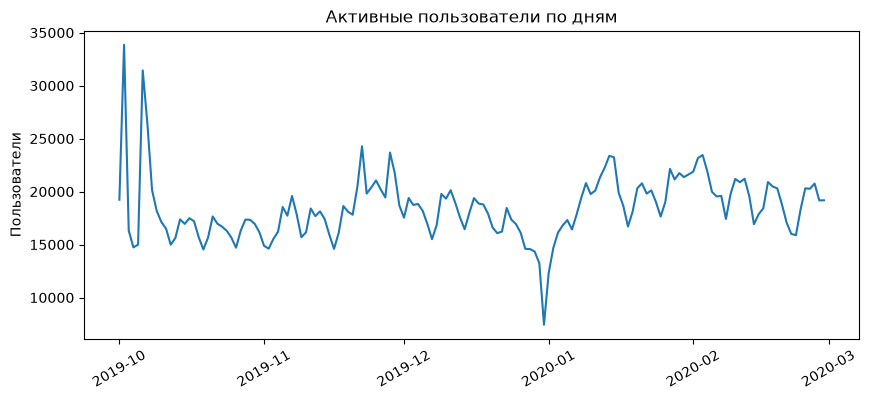

In [12]:
fig, ax = plt.subplots()
ax.plot(daily_stats["event_date"], daily_stats["users"])
ax.set(title="Активные пользователи по дням", ylabel="Пользователи")
plt.xticks(rotation=30)
plt.show()

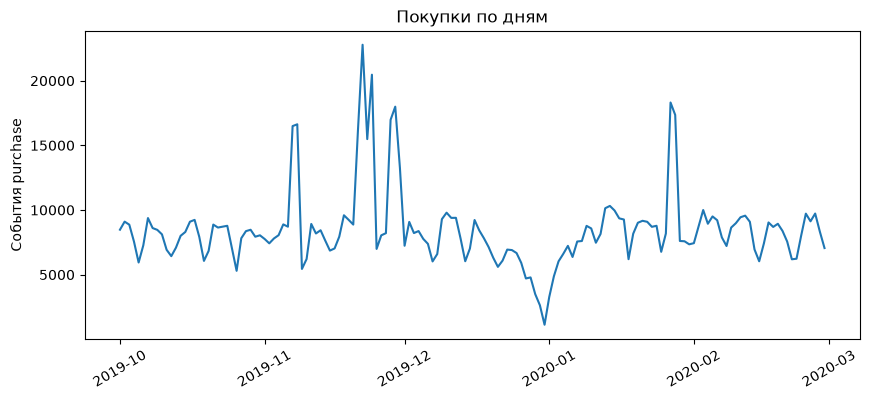

In [13]:
fig, ax = plt.subplots()
ax.plot(daily_stats["event_date"], daily_stats["purchase_events"])
ax.set(title="Покупки по дням", ylabel="События purchase")
plt.xticks(rotation=30)
plt.show()

- в данных наблюдаются регулярные недельные колебания активности пользователей и количества покупок => календарные характеристики могут быть полезны при построении моделей
- базовый уровень ежедневной активности меняется на протяжении периода наблюдения => это необходимо учитывать при временном разделении train, validation и test.
- в динамике покупок присутствуют выраженные всплески => для интерпретации надо дополнительно исследовать долю уникальных покупателей среди DAU
- в конце декабря наблюдается резкое снижение пользовательской активности и количества покупок
- для оценки устойчивости модели важно использовать хронологическое разделение выборок и анализировать качество предсказаний на разных временных периодах

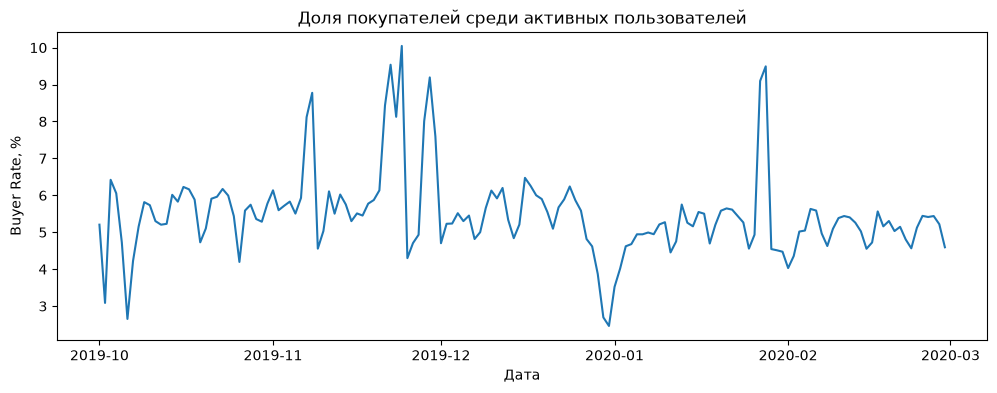

In [14]:
daily_buyers = (
    events
    .group_by("event_date")
    .agg(
        pl.col("user_id").n_unique().alias("users"),
        pl.col("user_id")
        .filter(pl.col("event_type") == "purchase")
        .n_unique()
        .alias("buyers"),
    )
    .with_columns(
        (pl.col("buyers") / pl.col("users")).alias("buyer_rate")
    )
    .sort("event_date")
    .collect(engine="streaming")
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    daily_buyers["event_date"],
    daily_buyers["buyer_rate"] * 100,
)

ax.set(
    title="Доля покупателей среди активных пользователей",
    ylabel="Buyer Rate, %",
    xlabel="Дата",
)

plt.show()

In [15]:
weekday_stats = (
    daily_stats
    .assign(weekday=lambda df: df["event_date"].dt.day_of_week)
    .groupby("weekday", as_index=False)
    .agg(
        avg_users=("users", "mean"),
        avg_purchase_events=("purchase_events", "mean"),
    )
)

weekday_stats

,weekday,avg_users,avg_purchase_events
0,0,19445.523810,8820.000000
1,1,18800.909091,8749.727273
2,2,19509.590909,8383.500000
3,3,18675.363636,9371.272727
4,4,17767.636364,9015.909091
5,5,16762.863636,7080.954545
6,6,18247.047619,7836.047619


Доп выводы по динамике:

- а пользовательской активности и количестве покупок наблюдается недельная сезонность (средний DAU в субботу примерно на 14% ниже, чем в среду + количество событий покупки также снижается в выходные)
- изменения количества покупок не полностью объясняются динамикой DAU (в отдельные периоды существенно изменяется и сама доля покупателей)
- распределение целевого действия покупки может быть нестабильным во времени => при моделировании необходимо использовать временное разделение выборок, проверять устойчивость качества на разных периодах и контролировать калибровку вероятностей
- день недели стоит рассмотреть как потенциальный признак

## 4. Retention

Для анализа будущих возвратов в продукт удобно иметь записи формат user_id x pdate


In [16]:
rebuild_cache = False # флаг пересоздания кэша

user_days_path = processed_dir / "user_days.parquet"

if rebuild_cache or not user_days_path.exists():
    (
        events
        .filter(
            pl.col("user_id").is_not_null()
            & pl.col("event_date").is_not_null()
        )
        .group_by("user_id", "event_date")
        .agg(
            pl.len().alias("events"),
            pl.col("user_session").n_unique().alias("sessions"),
            (pl.col("event_type") == "view").sum().alias("views"),
            (pl.col("event_type") == "cart").sum().alias("carts"),
            (pl.col("event_type") == "purchase").sum().alias("purchases"),
        )
        .sink_parquet(user_days_path)
    )

user_days = pl.scan_parquet(user_days_path)

In [17]:
# user_days_path = processed_dir / "user_days.parquet"

if not user_days_path.exists():
    (
        events.filter(pl.col("user_id").is_not_null() & pl.col("event_date").is_not_null())
        .group_by("user_id", "event_date")
        .agg(
            pl.len().alias("events"),
            pl.col("user_session").n_unique().alias("sessions"),
            (pl.col("event_type") == "view").sum().alias("views"),
            (pl.col("event_type") == "cart").sum().alias("carts"),
            (pl.col("event_type") == "purchase").sum().alias("purchases"),
        )
        .sink_parquet(user_days_path)
    )

user_days = pl.scan_parquet(user_days_path)
user_days.collect_schema()

Schema([('user_id', Int64),
        ('event_date', Date),
        ('events', UInt32),
        ('sessions', UInt32),
        ('views', UInt32),
        ('carts', UInt32),
        ('purchases', UInt32)])

In [18]:
user_stats = (
    user_days.group_by("user_id")
    .agg(
        pl.len().alias("active_days"),
        pl.col("events").sum().alias("events"),
        pl.col("sessions").sum().alias("sessions_sum_daily"),
        pl.col("purchases").sum().alias("purchases"),
    )
    .collect(engine="streaming")
)

user_stats.select(
    pl.len().alias("users"),
    pl.col("active_days").mean().alias("avg_active_days"),
    pl.col("active_days").median().alias("median_active_days"),
    pl.col("active_days").quantile(0.9).alias("p90_active_days"),
    (pl.col("active_days") == 1).mean().alias("one_day_user_share"),
).to_pandas()

,users,avg_active_days,median_active_days,p90_active_days,one_day_user_share
0,1639358,1.710977,1.0,3.0,0.766386


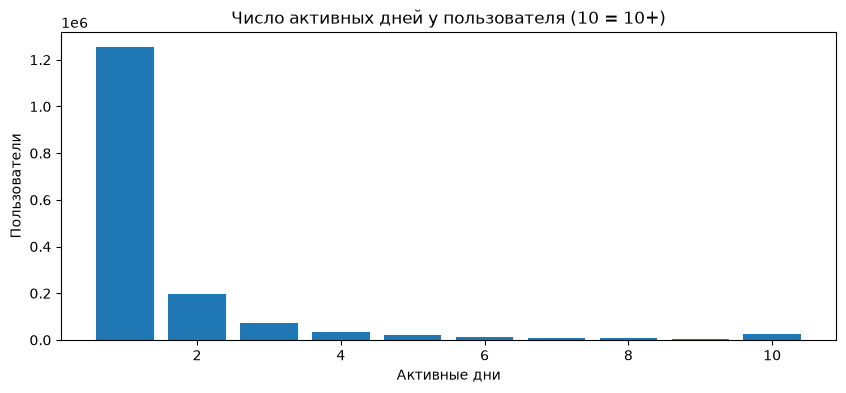

In [19]:
active_days = (
    user_stats.with_columns(pl.col("active_days").clip(upper_bound=10).alias("days_bucket"))
    .group_by("days_bucket")
    .len(name="users")
    .sort("days_bucket")
    .to_pandas()
)

fig, ax = plt.subplots()
ax.bar(active_days["days_bucket"], active_days["users"])
ax.set(title="Число активных дней у пользователя (10 = 10+)", xlabel="Активные дни", ylabel="Пользователи")
plt.show()

Выводы

- пользовательская активность разреженная: 76,6% пользователей наблюдались только в один календарный день за весь период, медиана - 1 активный день, а 90-й перцентиль - 3 дня
- ~23,4% пользователей проявляли активность в нескольких календарных днях, при этом данный показатель не является return rate на горизонтах 7/14 дней (он будет рассчитан отдельно на уровне `user_id × prediction_date` )
- разреженность истории ограничивает информативность длинных исторических окон и повышает значимость признаков давности последней активности, количества сессий и недавних действий
- при ежедневном формировании прогнозов пользователи без повторной активности могут создавать большое количество коррелирующих отрицательных наблюдений, это надо учитывать при формировании обучающей выборки и временной валидации
- пока сохраняем исходную постановку ежедневного batch scoring, но в дальнейшем необходимо сравнить популяции пользователей, активных за последние 7 и 30 дней, по объему, балансу целевых переменных и охвату будущих целевых действий

### Время между активными днями

In [20]:
return_gaps = (
    user_days.select("user_id", "event_date")
    .with_columns(
        pl.col("event_date").sort().diff().over("user_id").dt.total_days().alias("days_between")
    )
    .filter(pl.col("days_between").is_not_null())
    .group_by("days_between")
    .len(name="gaps")
    .sort("days_between")
    .collect(engine="streaming")
    .to_pandas()
)

return_gaps.head()

,days_between,gaps
0,1,348602
1,2,132279
2,3,89030
3,4,66211
4,5,51251


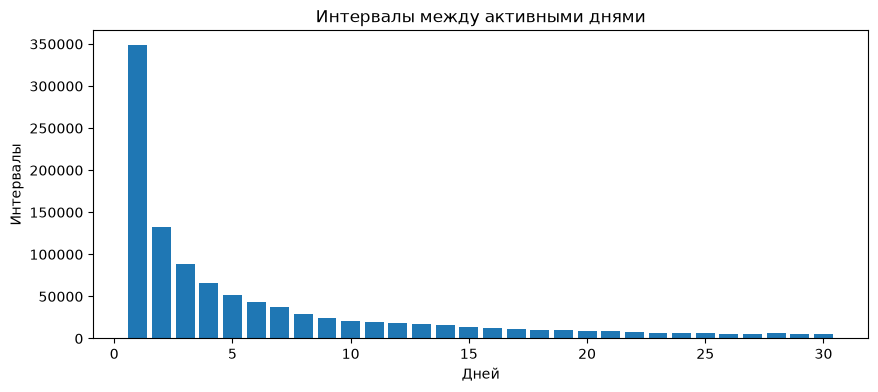

In [21]:
gap_plot = return_gaps[return_gaps["days_between"].between(1, 30)]
fig, ax = plt.subplots()
ax.bar(gap_plot["days_between"], gap_plot["gaps"])
ax.set(title="Интервалы между активными днями", xlabel="Дней", ylabel="Интервалы")
plt.show()

Выводы

- повторная активность пользователей быстро снижается с увеличением интервала между последовательными активными днями, наибольшее количество повторных посещений происходит уже на следующий день
- значительная часть повторной активности приходится на первые несколько дней после предыдущего посещения, но возвращения наблюдаются и через 10–30 дней
- полученные результаты предварительно подтверждают целесообразность рассмотрения горизонтов 7 и 14 дней для прогнозирования возвращения
- распределение интервалов не является оценкой вероятности возвращения: один пользователь может создавать несколько интервалов, а прогнозы будут рассчитываться на ежедневных срезах
- окончательный выбор горизонтов надо обосновать анализом целевых переменных на уровне `user_id × prediction_date` с учетом доступной истории наблюдений

Для предварительного EDA используем восемь дат прогнозирования с шагом 14 дней: это позволяет снизить вычислительную нагрузку и исследовать распределения таргетов
При этом в целевой системе inference планируется выполнять ежедневно, формирование окончательной обучающей выборки будет спроектировано отдельно с учетом пересечения целевых окон

## 5. Таргеты + исследование популяции для прогноза

Основной объект - user_id × prediction_date. Для каждого snapshot используем данные строго до начала prediction_date. Будущие события проверяем в диапазонах [t, t+7) и [t, t+14)

Сравним популяции с активностью за 7, 14 и 30 дней. Для return событием считается любая активность в будущем календарном дне; активность в день предсказания здесь допустима, тк признаки известны только до его начала.

In [22]:
first_date = overview["first_date"][0]
last_date = overview["last_date"][0]

prediction_dates = pd.date_range(
    start=pd.Timestamp(first_date) + pd.Timedelta(days=30),
    end=pd.Timestamp(last_date) - pd.Timedelta(days=13),
    freq="14D",
).date.tolist()

print(f"Дат срезов: {len(prediction_dates)}")
print(prediction_dates)

Дат срезов: 8
[datetime.date(2019, 10, 31), datetime.date(2019, 11, 14), datetime.date(2019, 11, 28), datetime.date(2019, 12, 12), datetime.date(2019, 12, 26), datetime.date(2020, 1, 9), datetime.date(2020, 1, 23), datetime.date(2020, 2, 6)]


In [23]:
from datetime import timedelta

snapshots = []

for prediction_date in prediction_dates:
    history = (
        user_days.filter(
            (pl.col("event_date") >= prediction_date - timedelta(days=30))
            & (pl.col("event_date") < prediction_date)
        )
        .group_by("user_id")
        .agg(
            pl.col("event_date").max().alias("last_active_date"),
            pl.col("events").sum().alias("events_30d"),
            pl.len().alias("active_days_30d"),
            pl.col("purchases").sum().alias("purchases_30d"),
        )
        .with_columns(
            (pl.lit(prediction_date) - pl.col("last_active_date")).dt.total_days().alias("recency_days")
        )
    )

    future = (
        user_days.filter(
            (pl.col("event_date") >= prediction_date)
            & (pl.col("event_date") < prediction_date + timedelta(days=14))
        )
        .group_by("user_id")
        .agg(
            (pl.col("event_date") < prediction_date + timedelta(days=7)).any().alias("return_7d"),
            pl.lit(True).any().alias("return_14d"),
            (pl.when(pl.col("event_date") < prediction_date + timedelta(days=7))
             .then(pl.col("purchases")).otherwise(0).sum() > 0).alias("purchase_7d"),
            (pl.col("purchases").sum() > 0).alias("purchase_14d"),
        )
    )

    snapshot = (
        history.join(future, on="user_id", how="left")
        .with_columns(pl.lit(prediction_date).alias("prediction_date"))
        .with_columns(pl.col(["return_7d", "return_14d", "purchase_7d", "purchase_14d"]).fill_null(False))
        .collect(engine="streaming")
    )
    snapshots.append(snapshot)

snapshots = pl.concat(snapshots)
print(f"Наблюдений: {snapshots.height:,}")
snapshots.head().to_pandas()

Наблюдений: 3,007,349


,user_id,last_active_date,events_30d,active_days_30d,purchases_30d,recency_days,return_7d,return_14d,purchase_7d,purchase_14d,prediction_date
0,514537945,2019-10-18,3,2,0,13,False,False,False,False,2019-10-31
1,232063059,2019-10-23,276,8,0,8,False,False,False,False,2019-10-31
2,563719096,2019-10-24,4,1,0,7,False,False,False,False,2019-10-31
3,479918965,2019-10-27,207,5,0,4,True,True,False,False,2019-10-31
4,557190703,2019-10-05,4,1,0,26,False,False,False,False,2019-10-31


In [24]:
target_cols = ["purchase_7d", "purchase_14d", "return_7d", "return_14d"]

population_results = []
for window in [7, 14, 30]:
    population = snapshots.filter(pl.col("recency_days") <= window)
    values = population.select(
        pl.len().alias("snapshots"),
        *[pl.col(name).mean().alias(name) for name in target_cols],
        *[pl.col(name).sum().alias(f"{name}_positives") for name in target_cols],
    ).to_dicts()[0]
    population_results.append({"activity_window": window, **values})

target_rates = pd.DataFrame(population_results)
target_rates

,activity_window,snapshots,purchase_7d,purchase_14d,return_7d,return_14d,purchase_7d_positives,purchase_14d_positives,return_7d_positives,return_14d_positives
0,7,847005,0.021291,0.035106,0.158075,0.213458,18034,29735,133890,180800
1,14,1533465,0.014665,0.025073,0.115712,0.163116,22489,38448,177440,250132
2,30,3007349,0.009092,0.016100,0.074145,0.109531,27343,48417,222981,329397


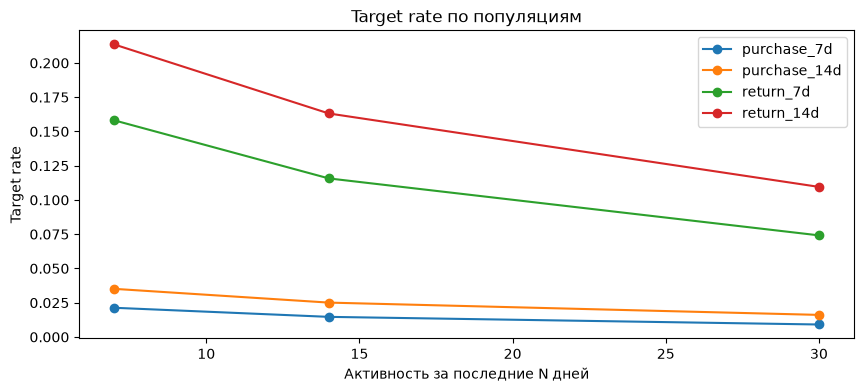

In [25]:
fig, ax = plt.subplots()
for target in target_cols:
    ax.plot(target_rates["activity_window"], target_rates[target], marker="o", label=target)
ax.set(title="Target rate по популяциям", xlabel="Активность за последние N дней", ylabel="Target rate")
ax.legend()
plt.show()

In [26]:
coverage = target_rates[["activity_window"]].copy()
for target in target_cols:
    denominator = target_rates.loc[target_rates["activity_window"] == 30, f"{target}_positives"].iloc[0]
    coverage[target] = (
        target_rates[f"{target}_positives"] / denominator
        if denominator else float("nan")
    )
coverage

,activity_window,purchase_7d,purchase_14d,return_7d,return_14d
0,7,0.659547,0.614144,0.600455,0.548882
1,14,0.822477,0.794101,0.795763,0.759363
2,30,1.000000,1.000000,1.000000,1.000000


Выводы

- на восьми датах прогнозирования сформировано ~3 млн наблюдений `user_id × prediction_date` для пользователей, активных за предыдущие 30 дней
- частота целевых действий существенно зависит от давности последней активности: для пользователей, активных за последние 7 дней, target rate заметно выше, чем для популяции с окном активности 30 дней
- покупка является редким целевым действием: target rate составляет 0,9–2,1% для горизонта 7 дней и 1,6–3,5% для 14 дней в зависимости от популяции, а для return значения существенно выше - 7,4–15,8% и 11,0–21,3% соответственно
- оба горизонта прогнозирования выглядят обоснованными: увеличение горизонта с 7 до 14 дней дает заметный прирост положительных наблюдений для обоих таргетов
- предварительно наиболее сбалансированной выглядит популяция пользователей, активных за последние 14 дней. Она сокращает количество прогнозируемых наблюдений примерно вдвое относительно 30-дневной популяции, сохраняя ~76–82% положительных исходов
- в целом выводы получены на восьми временных срезах, поэтому перед окончательным выбором популяции надо проверить их устойчивость на более частых датах прогнозирования

## 6. Признаки + простые эвристики

Здесь хотим увидеть, как target rate меняется в зависимости от recency

In [27]:
feature_check = (
    snapshots.with_columns(
        pl.when(pl.col("recency_days") == 1)
        .then(pl.lit("1"))
        .when(pl.col("recency_days") <= 3)
        .then(pl.lit("2-3"))
        .when(pl.col("recency_days") <= 7)
        .then(pl.lit("4-7"))
        .when(pl.col("recency_days") <= 14)
        .then(pl.lit("8-14"))
        .otherwise(pl.lit("15-30"))
        .alias("recency_group")
    )
    .group_by("recency_group")
    .agg(
        pl.len().alias("snapshots"),
        pl.col("purchase_7d").mean().alias("purchase_7d"),
        pl.col("return_7d").mean().alias("return_7d"),
    )
    .to_pandas()
)

order = ["1", "2-3", "4-7", "8-14", "15-30"]
feature_check["recency_group"] = pd.Categorical(feature_check["recency_group"], categories=order, ordered=True)
feature_check = feature_check.sort_values("recency_group")
feature_check

,recency_group,snapshots,purchase_7d,return_7d
3,1,150799,0.046605,0.283490
2,2-3,259288,0.023318,0.173872
1,4-7,436918,0.011352,0.105413
0,8-14,686460,0.006490,0.063441
4,15-30,1473884,0.003293,0.030899


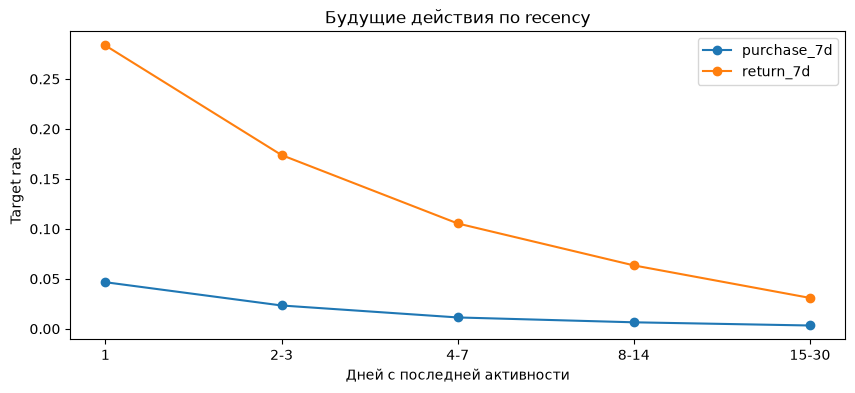

In [28]:
fig, ax = plt.subplots()
for target in ["purchase_7d", "return_7d"]:
    ax.plot(feature_check["recency_group"].astype(str), feature_check[target], marker="o", label=target)
ax.set(title="Будущие действия по recency", xlabel="Дней с последней активности", ylabel="Target rate")
ax.legend()
plt.show()

Выводы

- для обоих целевых действий видна выраженная монотонная зависимость от давности последней активности пользователя: чем меньше recency, тем выше вероятность покупки и возвращения в следующие 7 дней
- target rate покупки снижается с 4,66% для пользователей с recency 1 день до 0,33% при recency 15–30 дней (разница примерно в 14 раз). Для возвращения соответствующие значения составляют 28,35% и 3,09% (разница примерно в 9 раз)
- recency является перспективным поведенческим признаком и естественной основой для интерпретируемого бейзлайна, не требующего обучения модели
- несмотря на низкие target rate, пользователи с давней активностью могут обеспечивать заметную долю будущих целевых действий из-за большого размера популяции => выбор окна активности необходимо связывать с требованиями к охвату и сценариями использования прогнозов


## 7. Дополнительные проверки

- проверяем логическую согласованность таргетов
- проверка таргетов по исходным событиям
- устойчивость target rates по датам

In [29]:
target_checks = snapshots.select(
    (
        pl.col("purchase_7d") & ~pl.col("purchase_14d")
    ).sum().alias("invalid_purchase_horizon"),

    (
        pl.col("return_7d") & ~pl.col("return_14d")
    ).sum().alias("invalid_return_horizon"),

    (
        pl.col("purchase_7d") & ~pl.col("return_7d")
    ).sum().alias("purchase_without_return_7d"),

    (
        pl.col("purchase_14d") & ~pl.col("return_14d")
    ).sum().alias("purchase_without_return_14d"),

    pl.struct(["user_id", "prediction_date"])
    .n_unique()
    .alias("unique_snapshots"),
)

target_checks

invalid_purchase_horizon,invalid_return_horizon,purchase_without_return_7d,purchase_without_return_14d,unique_snapshots
u32,u32,u32,u32,u32
0,0,0,0,3007349


In [30]:
sample = snapshots.sample(
    n=min(500, snapshots.height),
    seed=42,
)

sample_users = sample.select(
    "user_id",
    "prediction_date",
)

future_events = (
    events
    .select("user_id", "event_date", "event_type")
    .join(sample_users.lazy(), on="user_id", how="inner")
    .filter(
        (pl.col("event_date") >= pl.col("prediction_date"))
        & (
            pl.col("event_date")
            < pl.col("prediction_date") + pl.duration(days=14)
        )
    )
)

target_validation = (
    future_events
    .group_by("user_id", "prediction_date")
    .agg(
        (
            pl.col("event_date")
            < pl.col("prediction_date") + pl.duration(days=7)
        ).any().alias("return_7d_check"),

        pl.len().gt(0).alias("return_14d_check"),

        (
            (pl.col("event_type") == "purchase")
            & (
                pl.col("event_date")
                < pl.col("prediction_date") + pl.duration(days=7)
            )
        ).any().alias("purchase_7d_check"),

        (pl.col("event_type") == "purchase")
        .any().alias("purchase_14d_check"),
    )
    .collect(engine="streaming")
)

In [31]:
validation = sample.join(
    target_validation,
    on=["user_id", "prediction_date"],
    how="left",
)

target_cols = [
    "purchase_7d",
    "purchase_14d",
    "return_7d",
    "return_14d",
]

validation = validation.with_columns(
    pl.col([f"{target}_check" for target in target_cols])
    .fill_null(False)
)

validation_results = validation.select(
    *[
        (
            pl.col(target) != pl.col(f"{target}_check")
        ).sum().alias(target)
        for target in target_cols
    ]
)

validation_results

purchase_7d,purchase_14d,return_7d,return_14d
u32,u32,u32,u32
0,0,0,0


In [32]:
target_cols = [
    "purchase_7d",
    "purchase_14d",
    "return_7d",
    "return_14d",
]

daily_target_rates = (
    snapshots
    .filter(pl.col("recency_days") <= 14)
    .group_by("prediction_date")
    .agg(
        pl.len().alias("users"),
        *[
            pl.col(target).mean().alias(target)
            for target in target_cols
        ],
    )
    .sort("prediction_date")
    .to_pandas()
)

daily_target_rates

,prediction_date,users,purchase_7d,purchase_14d,return_7d,return_14d
0,2019-10-31,173870,0.014683,0.027406,0.109547,0.156744
1,2019-11-14,178351,0.015032,0.032812,0.115065,0.173876
2,2019-11-28,194212,0.019443,0.028886,0.133514,0.177378
3,2019-12-12,198508,0.015123,0.023964,0.115572,0.157510
4,2019-12-26,189278,0.007692,0.015918,0.083607,0.127860
5,2020-01-09,166786,0.014450,0.023665,0.121407,0.165284
6,2020-01-23,214066,0.016985,0.025609,0.124004,0.175465
7,2020-02-06,218394,0.013622,0.022995,0.120791,0.168608


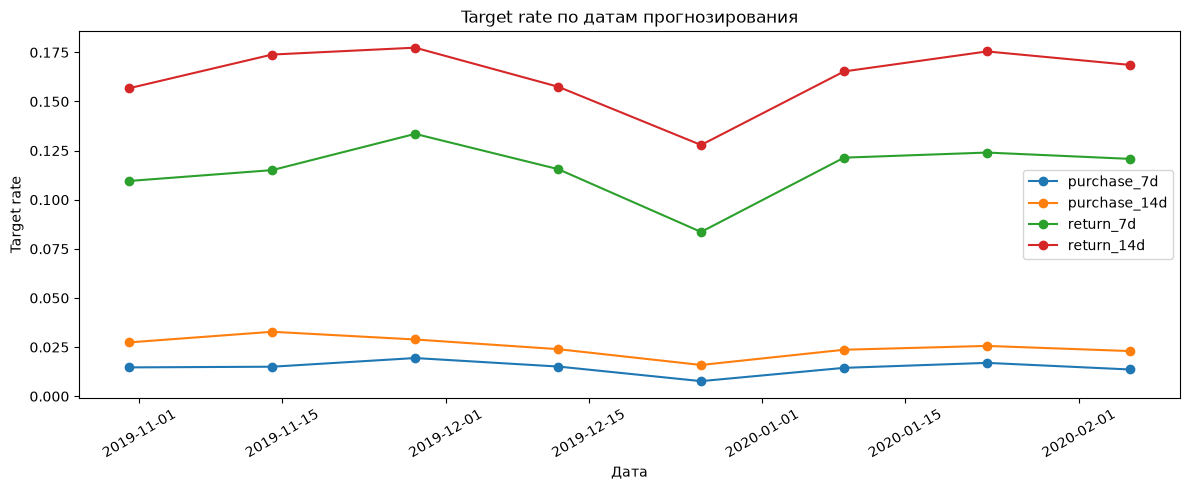

In [33]:
fig, ax = plt.subplots(figsize=(12, 5))

for target in target_cols:
    ax.plot(
        daily_target_rates["prediction_date"],
        daily_target_rates[target],
        marker="o",
        label=target,
    )

ax.set(
    title="Target rate по датам прогнозирования",
    xlabel="Дата",
    ylabel="Target rate",
)

ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [34]:
daily_target_rates[target_cols].agg(
    ["min", "median", "max", "std"]
).round(4)

,purchase_7d,purchase_14d,return_7d,return_14d
min,0.0077,0.0159,0.0836,0.1279
median,0.0149,0.0248,0.1182,0.1669
max,0.0194,0.0328,0.1335,0.1774
std,0.0033,0.0049,0.0147,0.0161


Выводы

- проверки логической согласованности четырех целевых переменных не выявили нарушений
- все комбинации `user_id × prediction_date` уникальны
- частота целевых действий заметно изменяется между датами прогнозирования: для `purchase_7d` наблюдаемый диапазон составляет 0,77–1,94%, для `return_7d` — 8,36–13,35%
- наиболее выраженное снижение target rate наблюдается 26 декабря 2019 года
- для обучения и оценки моделей необходимо использовать хронологическое разделение данных, учитывать пересечение горизонтов целевых переменных и проверять калибровку вероятностей на отдельных временных периодах
- основные таргеты и горизонты 7/14 дней сохраняются


## 8. Итоги EDA

В ходе исследования изучены состав и качество данных, повторная активность пользователей, временная динамика событий и распределения целевых переменных.

**Основные результаты**

- Датасет содержит 20,7 млн событий за пять месяцев наблюдений. Основные поля, необходимые для формирования таргетов, заполнены.
- Пользовательская активность разреженная: 76,6% пользователей наблюдались только в один календарный день.
- Покупка является редким целевым действием. В предварительно выбранной популяции пользователей, активных за последние 14 дней, target rate составляет около 1,5% для горизонта 7 дней и 2,5% для 14 дней.
- Recency демонстрирует выраженную связь с обоими целевыми действиями и рассматривается как основной кандидат для построения интерпретируемого baseline.
- Выявлена временная неоднородность частоты покупок и возвращений, которую необходимо учитывать при валидации и калибровке моделей.

**Предварительные решения**

| Компонент | Решение |
|---|---|
| Таргеты | Purchase, Return |
| Горизонты | 7 и 14 дней |
| Объект прогнозирования | `user_id × prediction_date` |
| Популяция | Активные за последние 14 дней |
| Baseline | Recency-based scoring |
| ML-валидация | Хронологическая с учётом горизонтов таргетов |
| Inference | Ежедневный batch |

**Ограничения исследования**

EDA выполнен на восьми временных срезах. Перед обучением моделей потребуется уточнить схему построения обучающих наблюдений, проверить устойчивость результатов на более частых датах и окончательно определить временные границы train/validation/test